# TB2 – Machine Learning (1FIS0300)
## Modelo 2: Clustering Jerárquico Aglomerativo (Ward)
**Caso de Estudio:** Ministerio de Salud (MINSA) – Certificado de Nacido Vivo (CNV)  
**Objetivo Metodológico:** Segmentación retrospectiva de perfiles maternos y obstétricos asociados a bajo peso al nacer (< 2 500 g) y prematuridad (< 37 semanas)  
**Muestra Establecida:** 30 000 registros independientes (Semilla 42)  
**Responsable:** Felix Torres Terreros


### 1. Marco Metodológico y Especificación Técnica

Este notebook implementa el **Clustering Jerárquico Aglomerativo** con criterio de mínima varianza (**Ward**) sobre una muestra reproducible de 30 000 registros.

* La elegibilidad usa únicamente controles de plausibilidad de variables de entrada; los desenlaces `Bajo_Peso_Nacer` y `Prematuro` no determinan qué registros entran a la muestra.
* Los desenlaces se reservan para caracterizar los clusters usando únicamente sus casos conocidos.
* Los faltantes se conservan mediante indicadores explícitos y se imputan de forma auditable. Los indicadores se reportan y Ward utiliza las 13 variables base imputadas.
* Se calcula una única matriz `linkage` y se reutiliza para explorar $k \in [3, 8]$, visualizar el dendrograma y obtener la partición final.


In [1]:
import os
import sys
import time
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Control de reproducibilidad y entorno gráfico
SEED = 42
N_MUESTRA = 30_000
N_EVAL_SIL = 5_000
K_CANDIDATOS = list(range(3, 9))
K_FINAL_CONFIG = 7

np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
PALETA = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']

TIEMPOS = {}
t_inicio_total = time.time()
os.makedirs('resultados', exist_ok=True)
print(f'Entorno configurado. Muestra objetivo: {N_MUESTRA:,} registros | Semilla: {SEED}')


Entorno configurado. Muestra objetivo: 30,000 registros | Semilla: 42


### 2. Carga del Dataset y Verificación de Integridad
Búsqueda de `NACIMIENTOS_CNV_LIMPIO.parquet` mediante rutas relativas y verificación de su hash SHA-256.


In [2]:
RUTAS_DATASET = [
    'data/NACIMIENTOS_CNV_LIMPIO.parquet',
    '../NACIMIENTOS_CNV_LIMPIO.parquet',
    'NACIMIENTOS_CNV_LIMPIO.parquet',
    '/content/drive/MyDrive/NACIMIENTOS_CNV_LIMPIO.parquet'
]

ruta_dataset = next((r for r in RUTAS_DATASET if os.path.exists(r)), None)
if ruta_dataset is None:
    raise FileNotFoundError('No se encontró NACIMIENTOS_CNV_LIMPIO.parquet en las rutas previstas.')

t0 = time.time()
with open(ruta_dataset, 'rb') as f:
    sha256_hash = hashlib.sha256(f.read()).hexdigest()

df_raw = pd.read_parquet(ruta_dataset)
TIEMPOS['t_carga'] = time.time() - t0

print(f'Archivo cargado desde: {ruta_dataset}')
print(f'SHA-256: {sha256_hash}')
print(f'Dimensiones leídas: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas')
print(f'Tiempo de lectura y hash: {TIEMPOS["t_carga"]:.2f} s')


Archivo cargado desde: data/NACIMIENTOS_CNV_LIMPIO.parquet
SHA-256: 24d734ca8cc39303da0c08b46007bcc5719e55208024e6e7725ee14e6f1cb55f
Dimensiones leídas: 5,065,065 filas × 24 columnas
Tiempo de lectura y hash: 0.55 s


### 3. Filtros de Plausibilidad y Extracción de 30 000 Registros

Se aplican únicamente filtros de plausibilidad sobre variables de entrada y se extraen exactamente 30 000 filas reproducibles sin reemplazo. Los desenlaces clínicos no se usan para excluir observaciones.


In [3]:
t0 = time.time()
# Filtro de plausibilidad independiente de los desenlaces clínicos.
# No se filtra por Bajo_Peso_Nacer, Prematuro ni variables postparto.
n_crudo = len(df_raw)
df_filtrado = df_raw.loc[df_raw['Edad_Madre'].between(10, 55)].copy()

n_elegibles = len(df_filtrado)
if n_elegibles < N_MUESTRA:
    raise ValueError(f'Registros elegibles ({n_elegibles}) insuficientes para la muestra de {N_MUESTRA}.')

# Muestreo aleatorio reproducible directo
df_30k = df_filtrado.sample(n=N_MUESTRA, random_state=SEED).copy()

# Desenlaces solo para perfilado posterior; los faltantes permanecen como NaN.
y_bp = df_30k['Bajo_Peso_Nacer'].map({'SI': 1.0, 'NO': 0.0}).astype('float32').to_numpy()
y_pre = df_30k['Prematuro'].map({'SI': 1.0, 'NO': 0.0}).astype('float32').to_numpy()

print(f'Registros crudos: {n_crudo:,} | Elegibles por plausibilidad: {n_elegibles:,} (eliminados: {n_crudo - n_elegibles:,})')
print(f'Muestra de trabajo: {len(df_30k):,} registros exactos.')
print(f'Bajo peso conocidos: {np.isfinite(y_bp).sum():,} | faltantes: {np.isnan(y_bp).sum():,}')
print(f'Prematuridad conocida: {np.isfinite(y_pre).sum():,} | faltantes: {np.isnan(y_pre).sum():,}')
print('Distribución temporal (Año de Nacimiento):')
print(df_30k.FecNac_Año.value_counts().sort_index().to_dict())


Registros crudos: 5,065,065 | Elegibles por plausibilidad: 5,064,963 (eliminados: 102)
Muestra de trabajo: 30,000 registros exactos.
Bajo peso conocidos: 29,995 | faltantes: 5
Prematuridad conocida: 30,000 | faltantes: 0
Distribución temporal (Año de Nacimiento):
{2015: 2434, 2016: 2685, 2017: 2870, 2018: 2902, 2019: 2964, 2020: 2811, 2021: 2664, 2022: 2748, 2023: 2525, 2024: 2262, 2025: 2229, 2026: 906}


### 4. Ingeniería de Características (13 Variables Base + Indicadores de Faltante)

Se transforman variables maternas y obstétricas de entrada. Cada faltante de una variable base se conserva con un indicador explícito antes de una imputación auditable.


In [4]:
EDU_MAP = {
    'NINGUN NIVEL/ILETRADO': 0, 'INCIAL/PRE-ESCOLAR': 0, 'PRIMARIA INCOMPLETA': 1,
    'PRIMARIA COMPLETA': 2, 'SECUNDARIA INCOMPLETA': 3, 'SECUNDARIA COMPLETA': 4,
    'SUPERIOR NO UNIV. INCOMPLETA': 5, 'SUPERIOR UNIV. INCOMPLETA': 5,
    'SUPERIOR NO UNIV. COMPLETA': 6, 'SUPERIOR UNIV. COMPLETA': 7
}
ORD5_MAP = {'1': 1, '2': 2, '3': 3, '4': 4, '>=5': 5}

def parse_perdidas(v):
    if pd.isna(v):
        return np.nan
    if v == 'NINGUNO':
        return 0.0
    if str(v).startswith('11'):
        return 11.0
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan

REGION_MAP = {
    '01': 'SELVA', '02': 'SIERRA', '03': 'SIERRA', '04': 'SIERRA', '05': 'SIERRA', '06': 'SIERRA',
    '07': 'COSTA', '08': 'SIERRA', '09': 'SIERRA', '10': 'SIERRA', '11': 'COSTA', '12': 'SIERRA',
    '13': 'COSTA', '14': 'COSTA', '15': 'COSTA', '16': 'SELVA', '17': 'SELVA', '18': 'COSTA',
    '19': 'SIERRA', '20': 'COSTA', '21': 'SIERRA', '22': 'SELVA', '23': 'COSTA', '24': 'COSTA', '25': 'SELVA'
}
NO_CALIF = {'FAMILIAR', 'PARTERA', 'NADIE(AUTOAYUDA)', 'OTRO'}

X = pd.DataFrame(index=df_30k.index)
X['edad_madre'] = df_30k.Edad_Madre.astype('float32')
X['educacion'] = df_30k['Nivel_Intrucción_Madre'].map(EDU_MAP).astype('float32')
X['n_embarazos'] = df_30k.Num_embar_madre.map(ORD5_MAP).astype('float32')
X['hijos_vivos'] = df_30k.Hijos_vivo_madre.map(ORD5_MAP).astype('float32')
X['perdidas_previas'] = df_30k.nacmuer_abort_madre.map(parse_perdidas).clip(upper=3).astype('float32')
X['parto_multiple'] = df_30k.Tipo_Parto.map({'UNICO': 0.0, 'DOBLE': 1.0, 'TRIPLE': 1.0, 'MAS DE TRES': 1.0}).astype('float32')
X['cesarea'] = df_30k.Condicion_Parto.map({'CESAREA': 1.0, 'EUTOCICO': 0.0, 'INSTRUMENTADO': 0.0}).astype('float32')
X['fuera_eess'] = df_30k.Lugar_Nacido.map(lambda v: np.nan if pd.isna(v) else float(v != 'ESTABLECIMIENTO DE SALUD')).astype('float32')
X['atencion_no_calif'] = df_30k.Atiende_Parto.map(lambda v: np.nan if pd.isna(v) else float(v in NO_CALIF)).astype('float32')
X['sis'] = df_30k.Financiador_Parto.map(lambda v: np.nan if pd.isna(v) else float(v == 'SIS')).astype('float32')
X['extranjera'] = df_30k.Pais_Madre.map(lambda v: np.nan if pd.isna(v) else float(v != 'PERU')).astype('float32')

depto = df_30k.IdUbigeoInei.astype('string').str[:2]
region = depto.map(REGION_MAP)
X['sierra'] = region.map(lambda v: np.nan if pd.isna(v) else float(v == 'SIERRA')).astype('float32')
X['selva'] = region.map(lambda v: np.nan if pd.isna(v) else float(v == 'SELVA')).astype('float32')

BASE_FEATURES = list(X.columns)
# Los indicadores se calculan antes de imputar y se mantienen en la matriz final.
missing_masks = {col: X[col].isna() for col in BASE_FEATURES}
for col, mask in missing_masks.items():
    if mask.any():
        X[f'missing_{col}'] = mask.astype('float32')

# Imputación simple y auditable: mediana para conteos/edad; moda para categorías codificadas.
NUMERIC_MEDIAN = {'edad_madre', 'perdidas_previas'}
imputaciones = {}
for col in BASE_FEATURES:
    n_nulos = int(X[col].isna().sum())
    if n_nulos == 0:
        imputaciones[col] = {'nulos': 0, 'estrategia': 'sin_imputacion'}
        continue
    if col in NUMERIC_MEDIAN:
        valor = float(X[col].median())
        estrategia = 'mediana'
    else:
        valor = float(X[col].mode(dropna=True).iloc[0])
        estrategia = 'moda'
    X[col] = X[col].fillna(valor)
    imputaciones[col] = {'nulos': n_nulos, 'estrategia': estrategia, 'valor_imputado': valor}

missing_summary = {col: int(mask.sum()) for col, mask in missing_masks.items()}
if X.isna().any().any():
    raise ValueError('Persisten valores faltantes en la matriz de características.')

# Ward utiliza las variables base; los indicadores se conservan para auditoría.
X_model = X[BASE_FEATURES].copy()
print(f'Matriz de características auditada: {X.shape[1]} columnas ({len(BASE_FEATURES)} base + {X.shape[1] - len(BASE_FEATURES)} indicadores).')
print(f'Matriz usada por Ward: {X_model.shape[1]} variables base.')
print('Valores faltantes por variable base:', missing_summary)
print('Imputaciones realizadas:', imputaciones)


Matriz de características auditada: 24 columnas (13 base + 11 indicadores).
Matriz usada por Ward: 13 variables base.
Valores faltantes por variable base: {'edad_madre': 0, 'educacion': 19, 'n_embarazos': 280, 'hijos_vivos': 239, 'perdidas_previas': 2618, 'parto_multiple': 44, 'cesarea': 71, 'fuera_eess': 1, 'atencion_no_calif': 19, 'sis': 238, 'extranjera': 0, 'sierra': 51, 'selva': 51}
Imputaciones realizadas: {'edad_madre': {'nulos': 0, 'estrategia': 'sin_imputacion'}, 'educacion': {'nulos': 19, 'estrategia': 'moda', 'valor_imputado': 4.0}, 'n_embarazos': {'nulos': 280, 'estrategia': 'moda', 'valor_imputado': 1.0}, 'hijos_vivos': {'nulos': 239, 'estrategia': 'moda', 'valor_imputado': 1.0}, 'perdidas_previas': {'nulos': 2618, 'estrategia': 'mediana', 'valor_imputado': 0.0}, 'parto_multiple': {'nulos': 44, 'estrategia': 'moda', 'valor_imputado': 0.0}, 'cesarea': {'nulos': 71, 'estrategia': 'moda', 'valor_imputado': 0.0}, 'fuera_eess': {'nulos': 1, 'estrategia': 'moda', 'valor_imputado

### 5. Estandarización sobre los 30 000 Registros
Se ajusta `StandardScaler` sobre las 13 variables base ya imputadas. Los indicadores de faltante se conservan únicamente para auditoría.


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_model).astype('float32')
TIEMPOS['t_preparacion'] = time.time() - t0

print(f'Matriz escalada: {X_scaled.shape} | Memoria: {X_scaled.nbytes / (1024**2):.2f} MB')
print(f'Tiempo de preparación y escalado: {TIEMPOS["t_preparacion"]:.2f} s')


Matriz escalada: (30000, 13) | Memoria: 1.49 MB
Tiempo de preparación y escalado: 1.31 s


### 6. Matriz de Enlace Única (Ward Linkage)
Cálculo de la matriz aglomerativa mediante el criterio de mínima varianza de Ward. Esta matriz se reutiliza para todos los análisis posteriores sin recálculos.


In [6]:
t0 = time.time()
print('Calculando enlace de Ward sobre las 30,000 observaciones...')
Z_ward = linkage(X_scaled, method='ward', metric='euclidean')
TIEMPOS['t_ward'] = time.time() - t0

print(f'Enlace Ward completado en {TIEMPOS["t_ward"]:.2f} segundos.')
print(f'Dimensiones de Z_ward: {Z_ward.shape}')


Calculando enlace de Ward sobre las 30,000 observaciones...
Enlace Ward completado en 11.14 segundos.
Dimensiones de Z_ward: (29999, 4)


### 7. Comparación de Candidatos $k \in [3, 8]$

Se evalúan las particiones derivadas de una única matriz Ward. Silhouette se calcula sobre un subconjunto fijo de 5 000 observaciones y Davies–Bouldin sobre los 30 000 registros.

La partición final usa **k=7**. En la comparación, k=7 presenta Silhouette=0.2180 y Davies–Bouldin=1.3187; k=8 presenta Silhouette=0.2200 y Davies–Bouldin=1.3229. Estos valores se contrastan con los perfiles y tamaños de cluster.

Referencias primarias: [SciPy `linkage` y criterio Ward](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html), [scikit-learn `silhouette_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) y [guía de análisis de Silhouette](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html).


In [7]:
t0 = time.time()
rng_eval = np.random.default_rng(SEED)
idx_sil_5k = rng_eval.choice(N_MUESTRA, size=N_EVAL_SIL, replace=False)
X_eval_sil = X_scaled[idx_sil_5k]

resultados_k = []
for k_cand in K_CANDIDATOS:
    etiquetas_cand = fcluster(Z_ward, t=k_cand, criterion='maxclust')
    conteos_cand = pd.Series(etiquetas_cand).value_counts()
    sil = float(silhouette_score(X_eval_sil, etiquetas_cand[idx_sil_5k]))
    db = float(davies_bouldin_score(X_scaled, etiquetas_cand))
    resultados_k.append({
        'k': k_cand,
        'Silhouette_5k': sil,
        'Davies_Bouldin_30k': db,
        'min_cluster_share': float(conteos_cand.min() / N_MUESTRA),
        'max_cluster_share': float(conteos_cand.max() / N_MUESTRA)
    })

df_metricas_k = pd.DataFrame(resultados_k)
if K_FINAL_CONFIG not in K_CANDIDATOS:
    raise ValueError(f'K_FINAL_CONFIG={K_FINAL_CONFIG} debe estar dentro de K_CANDIDATOS.')
K_FINAL = K_FINAL_CONFIG
regla_seleccion = 'k7_comparacion_silhouette_davies_bouldin'
df_metricas_k.to_csv('resultados/metricas_k.csv', index=False)
TIEMPOS['t_eval_k'] = time.time() - t0

print('Comparativa de particiones derivadas del enlace Ward:')
print(df_metricas_k.to_string(index=False))
print(f'Partición final: k={K_FINAL}')
print(f'Tiempo de evaluación de métricas: {TIEMPOS["t_eval_k"]:.2f} s')


Comparativa de particiones derivadas del enlace Ward:
 k  Silhouette_5k  Davies_Bouldin_30k  min_cluster_share  max_cluster_share
 3       0.160755            2.184506             0.0241           0.618433
 4       0.163513            1.758370             0.0182           0.618433
 5       0.159000            1.674226             0.0182           0.388233
 6       0.173476            1.483593             0.0182           0.364167
 7       0.218044            1.318689             0.0182           0.364167
 8       0.219987            1.322861             0.0182           0.364167
Partición final: k=7
Tiempo de evaluación de métricas: 0.76 s


### 8. Dendrograma Truncado y Altura de Corte

Se visualiza el dendrograma con la altura calculada para el $k$ final configurado.


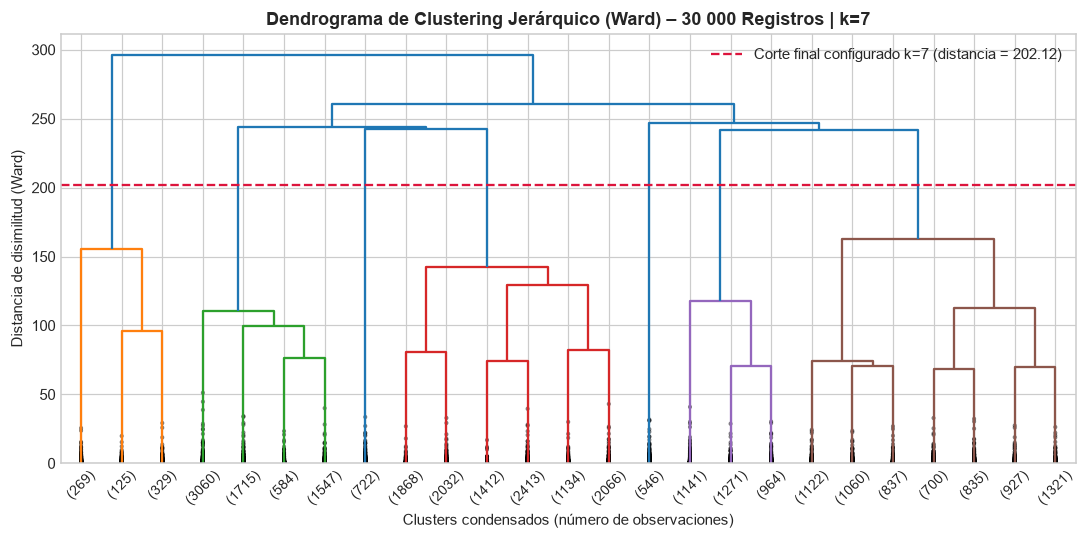

Altura de corte calculada para k=7: 202.1237


In [8]:
altura_corte_final = float((Z_ward[-(K_FINAL - 1), 2] + Z_ward[-K_FINAL, 2]) / 2.0)

plt.figure(figsize=(10, 5))
plt.title(f'Dendrograma de Clustering Jerárquico (Ward) – 30 000 Registros | k={K_FINAL}', fontsize=12, fontweight='bold')
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=45.,
    leaf_font_size=9.,
    show_contracted=True,
    color_threshold=altura_corte_final
)
plt.xlabel('Clusters condensados (número de observaciones)')
plt.ylabel('Distancia de disimilitud (Ward)')
plt.axhline(y=altura_corte_final, color='crimson', linestyle='--', label=f'Corte final configurado k={K_FINAL} (distancia = {altura_corte_final:.2f})')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('resultados/dendrograma_ward.png', dpi=150)
plt.show()
print(f'Altura de corte calculada para k={K_FINAL}: {altura_corte_final:.4f}')


### 9. Partición final: k=7

Las etiquetas se obtienen mediante el corte k=7 de la matriz de enlace Ward.


In [9]:
# fcluster asigna etiquetas consecutivas; se normalizan a 0-indexed para los resultados.
etiquetas_finales = fcluster(Z_ward, t=K_FINAL, criterion='maxclust') - 1

conteo_grupos = pd.Series(etiquetas_finales).value_counts().sort_index()
if len(conteo_grupos) != K_FINAL:
    raise ValueError(f'La partición no produjo exactamente {K_FINAL} grupos.')

print(f'Partición final: k={K_FINAL}')
print('Distribución de los 30 000 registros por cluster:')
for c, cnt in conteo_grupos.items():
    print(f'  Cluster {c}: {cnt:,} casos ({cnt/N_MUESTRA:.2%})')


Partición final: k=7
Distribución de los 30 000 registros por cluster:
  Cluster 0: 723 casos (2.41%)
  Cluster 1: 6,906 casos (23.02%)
  Cluster 2: 722 casos (2.41%)
  Cluster 3: 10,925 casos (36.42%)
  Cluster 4: 546 casos (1.82%)
  Cluster 5: 3,376 casos (11.25%)
  Cluster 6: 6,802 casos (22.67%)


### 10. Perfilado Retrospectivo de Desenlaces Conocidos

Los desenlaces se describen por cluster sin imputarlos: cada tasa usa como denominador únicamente los casos conocidos de ese desenlace.


=== TASAS DE EVENTOS CLÍNICOS CONOCIDOS POR CLUSTER ===
 cluster  total_registros  n_bajo_peso_conocido  n_prematuro_conocido  pct_poblacion  tasa_bajo_peso_pct  tasa_prematuro_pct
       0              723                   720                   723           2.41                6.94            4.560000
       1             6906                  6906                  6906          23.02                4.24            5.650000
       2              722                   722                   722           2.41                9.14            8.310000
       3            10925                 10924                 10925          36.42                5.63            5.400000
       4              546                   546                   546           1.82               56.23           58.790001
       5             3376                  3375                  3376          11.25                6.96            7.020000
       6             6802                  6802                  6802

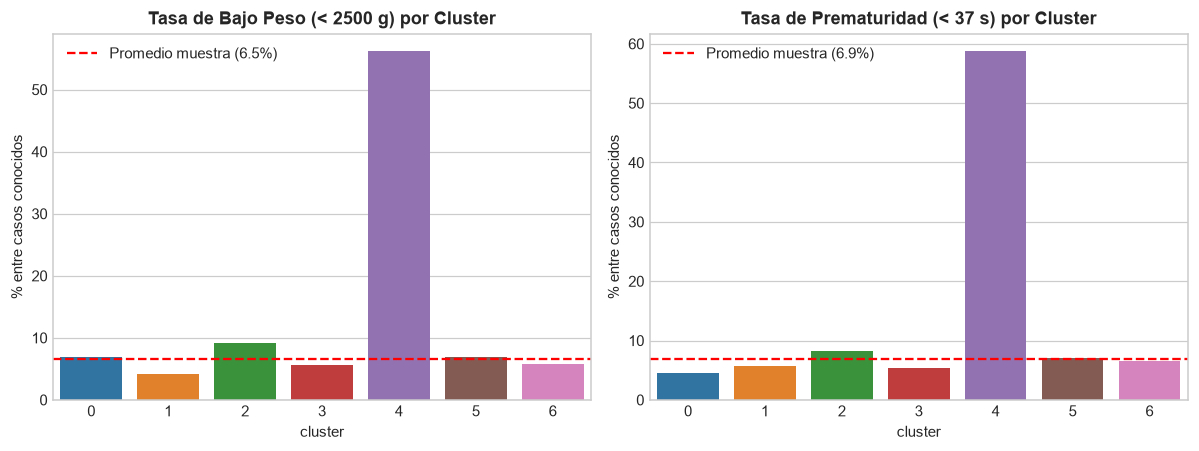

In [10]:
df_analisis = pd.DataFrame({
    'id_origen': df_30k.index,
    'cluster': etiquetas_finales,
    'bajo_peso': y_bp,
    'prematuro': y_pre
})

perfiles_clinicos = df_analisis.groupby('cluster').agg(
    total_registros=('cluster', 'size'),
    n_bajo_peso_conocido=('bajo_peso', 'count'),
    n_prematuro_conocido=('prematuro', 'count'),
    tasa_bajo_peso=('bajo_peso', 'mean'),
    tasa_prematuro=('prematuro', 'mean')
).reset_index()

perfiles_clinicos['pct_poblacion'] = (perfiles_clinicos['total_registros'] / N_MUESTRA) * 100
perfiles_clinicos['tasa_bajo_peso_pct'] = perfiles_clinicos['tasa_bajo_peso'] * 100
perfiles_clinicos['tasa_prematuro_pct'] = perfiles_clinicos['tasa_prematuro'] * 100
perfiles_clinicos.to_csv('resultados/perfiles_clusters.csv', index=False)

print('=== TASAS DE EVENTOS CLÍNICOS CONOCIDOS POR CLUSTER ===')
print(perfiles_clinicos[['cluster', 'total_registros', 'n_bajo_peso_conocido', 'n_prematuro_conocido', 'pct_poblacion', 'tasa_bajo_peso_pct', 'tasa_prematuro_pct']].round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.barplot(data=perfiles_clinicos, x='cluster', y='tasa_bajo_peso_pct', hue='cluster', ax=ax[0], palette=PALETA[:K_FINAL], legend=False)
ax[0].set_title('Tasa de Bajo Peso (< 2500 g) por Cluster', fontweight='bold')
ax[0].set_ylabel('% entre casos conocidos')
ax[0].axhline(np.nanmean(y_bp) * 100, color='red', linestyle='--', label=f'Promedio muestra ({np.nanmean(y_bp):.1%})')
ax[0].legend()

sns.barplot(data=perfiles_clinicos, x='cluster', y='tasa_prematuro_pct', hue='cluster', ax=ax[1], palette=PALETA[:K_FINAL], legend=False)
ax[1].set_title('Tasa de Prematuridad (< 37 s) por Cluster', fontweight='bold')
ax[1].set_ylabel('% entre casos conocidos')
ax[1].axhline(np.nanmean(y_pre) * 100, color='red', linestyle='--', label=f'Promedio muestra ({np.nanmean(y_pre):.1%})')
ax[1].legend()

plt.tight_layout()
plt.savefig('resultados/tasas_riesgo_clusters.png', dpi=150)
plt.show()


### 11. Caracterización Multivariable y Heatmap Z-Score
Promedios de variables originales y mapa de calor estandarizado por cluster.


=== PROMEDIO DE VARIABLES ORIGINALES POR CLUSTER ===
cluster                    0          1      2          3          4      5  \
edad_madre         26.860001  30.120001  26.57  24.809999  30.440001  25.99   
educacion           3.020000   5.430000   4.71   3.910000   4.240000   3.54   
n_embarazos         2.820000   2.040000   2.02   1.700000   2.610000   2.56   
hijos_vivos         2.630000   1.810000   1.78   1.680000   2.840000   2.28   
perdidas_previas    0.210000   0.220000   0.27   0.000000   0.360000   0.31   
parto_multiple      0.000000   0.000000   0.00   0.000000   1.000000   0.00   
cesarea             0.130000   0.590000   0.49   0.290000   0.860000   0.29   
fuera_eess          0.830000   0.000000   0.01   0.000000   0.010000   0.00   
atencion_no_calif   0.630000   0.000000   0.00   0.000000   0.000000   0.00   
sis                 0.640000   0.000000   0.82   1.000000   0.630000   0.87   
extranjera          0.000000   0.000000   1.00   0.000000   0.020000   0.00   

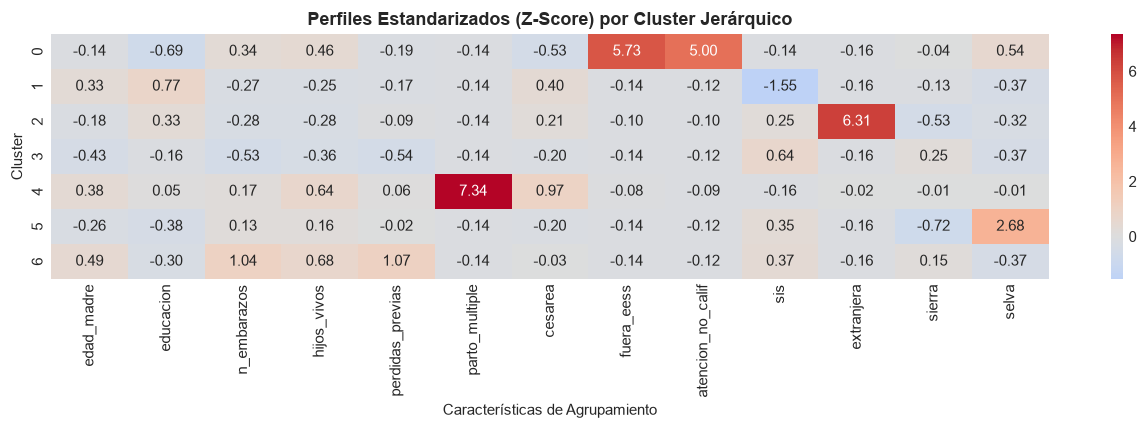

In [11]:
df_feat_analisis = X_model.copy()
df_feat_analisis['cluster'] = etiquetas_finales
medias_originales = df_feat_analisis.groupby('cluster').mean()
print('=== PROMEDIO DE VARIABLES ORIGINALES POR CLUSTER ===')
print(medias_originales.T.round(2))

# Heatmap de perfiles Z-Score
medias_z = pd.DataFrame(X_scaled, columns=list(X_model.columns)).groupby(etiquetas_finales).mean()
plt.figure(figsize=(12, 4))
sns.heatmap(medias_z, cmap='coolwarm', annot=True, fmt='.2f', cbar=True, center=0)
plt.title('Perfiles Estandarizados (Z-Score) por Cluster Jerárquico', fontsize=12, fontweight='bold')
plt.xlabel('Características de Agrupamiento')
plt.ylabel('Cluster')
plt.tight_layout()
plt.savefig('resultados/heatmap_perfiles_z.png', dpi=150)
plt.show()


### 12. Persistencia de Artefactos y Manifiesto de Ejecución

Se exportan las etiquetas, métricas, perfiles y un manifiesto con la configuración, trazabilidad, faltantes e imputaciones.


In [12]:
# 1. Guardar etiquetas con identificadores de origen
df_analisis.to_csv('resultados/etiquetas_30k.csv', index=False)

# 2. Medir tiempo total
TIEMPOS['t_total_notebook'] = time.time() - t_inicio_total

# 3. Manifiesto
metrica_final = df_metricas_k.loc[df_metricas_k.k == K_FINAL].iloc[0]
manifiesto = {
    'proyecto': 'TB2 - Machine Learning (UPC)',
    'modelo': 'Clustering Jerárquico Aglomerativo (Ward)',
    'interpretacion': 'segmentacion retrospectiva de perfiles maternos y obstetricos asociados a desenlaces conocidos',
    'semilla': SEED,
    'n_muestra': N_MUESTRA,
    'n_eval_silhouette': N_EVAL_SIL,
    'k_candidatos': K_CANDIDATOS,
    'k_final_configurado': K_FINAL,
    'regla_seleccion': regla_seleccion,
    'n_crudo': int(n_crudo),
    'n_elegibles': int(n_elegibles),
    'outcomes_usados_para_elegibilidad': False,
    'outcome_missing_counts': {
        'Bajo_Peso_Nacer': int(np.isnan(y_bp).sum()),
        'Prematuro': int(np.isnan(y_pre).sum())
    },
    'dataset_sha256': sha256_hash,
    'versiones': {
        'python': sys.version.split()[0],
        'scipy': getattr(sys.modules.get('scipy'), '__version__', 'N/A'),
        'sklearn': getattr(sys.modules.get('sklearn'), '__version__', 'N/A'),
        'pandas': pd.__version__,
        'numpy': np.__version__
    },
    'metricas_finales': {
        'silhouette_5k': float(metrica_final['Silhouette_5k']),
        'davies_bouldin_30k': float(metrica_final['Davies_Bouldin_30k']),
        'min_cluster_share': float(metrica_final['min_cluster_share']),
        'max_cluster_share': float(metrica_final['max_cluster_share'])
    },
    'tiempos_segundos': {k: round(v, 2) for k, v in TIEMPOS.items()},
    'conteo_clusters': {str(int(k)): int(v) for k, v in conteo_grupos.items()},
    'missing_counts_variables_base': missing_summary,
    'imputaciones': imputaciones
}

with open('resultados/manifiesto_ejecucion.json', 'w', encoding='utf-8') as f:
    json.dump(manifiesto, f, indent=2, ensure_ascii=False)

print('Manifiesto generado en resultados/manifiesto_ejecucion.json:')
print(json.dumps(manifiesto, indent=2, ensure_ascii=False))


Manifiesto generado en resultados/manifiesto_ejecucion.json:
{
  "proyecto": "TB2 - Machine Learning (UPC)",
  "modelo": "Clustering Jerárquico Aglomerativo (Ward)",
  "interpretacion": "segmentacion retrospectiva de perfiles maternos y obstetricos asociados a desenlaces conocidos",
  "semilla": 42,
  "n_muestra": 30000,
  "n_eval_silhouette": 5000,
  "k_candidatos": [
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "k_final_configurado": 7,
  "regla_seleccion": "k7_comparacion_silhouette_davies_bouldin",
  "n_crudo": 5065065,
  "n_elegibles": 5064963,
  "outcomes_usados_para_elegibilidad": false,
  "outcome_missing_counts": {
    "Bajo_Peso_Nacer": 5,
    "Prematuro": 0
  },
  "dataset_sha256": "24d734ca8cc39303da0c08b46007bcc5719e55208024e6e7725ee14e6f1cb55f",
  "versiones": {
    "python": "3.12.9",
    "scipy": "1.18.1",
    "sklearn": "1.9.1",
    "pandas": "3.0.6",
    "numpy": "2.5.4"
  },
  "metricas_finales": {
    "silhouette_5k": 0.21804355084896088,
    "davies_bouldin_30k"

In [13]:
# Resumen de resultados
mejor_sil = df_metricas_k.loc[df_metricas_k['Silhouette_5k'].idxmax()]
mejor_db = df_metricas_k.loc[df_metricas_k['Davies_Bouldin_30k'].idxmin()]
metricas_final = df_metricas_k.loc[df_metricas_k.k == K_FINAL].iloc[0]
cluster_mayor_bp = perfiles_clinicos.loc[perfiles_clinicos['tasa_bajo_peso'].idxmax(), 'cluster']
cluster_mayor_pre = perfiles_clinicos.loc[perfiles_clinicos['tasa_prematuro'].idxmax(), 'cluster']

print('=== CONCLUSIONES METODOLÓGICAS ===')
print(f'1. Ward se calculó una sola vez sobre {N_MUESTRA:,} registros y se reutilizó para todos los cortes.')
print(f'2. Partición final: k={K_FINAL}.')
print(f'3. Para k={K_FINAL}: Silhouette={metricas_final.Silhouette_5k:.4f} y Davies–Bouldin={metricas_final.Davies_Bouldin_30k:.4f}. En la tabla, el mayor Silhouette fue k={int(mejor_sil.k)} y el menor Davies–Bouldin k={int(mejor_db.k)}.')
print(f'4. El cluster {int(cluster_mayor_bp)} presentó la mayor tasa observada de bajo peso entre casos conocidos; el cluster {int(cluster_mayor_pre)} presentó la mayor tasa observada de prematuridad entre casos conocidos.')
print('5. Estos perfiles son asociaciones retrospectivas y no constituyen un modelo predictivo ni una estimación nacional.')


=== CONCLUSIONES METODOLÓGICAS ===
1. Ward se calculó una sola vez sobre 30,000 registros y se reutilizó para todos los cortes.
2. Partición final: k=7.
3. Para k=7: Silhouette=0.2180 y Davies–Bouldin=1.3187. En la tabla, el mayor Silhouette fue k=8 y el menor Davies–Bouldin k=7.
4. El cluster 4 presentó la mayor tasa observada de bajo peso entre casos conocidos; el cluster 4 presentó la mayor tasa observada de prematuridad entre casos conocidos.
5. Estos perfiles son asociaciones retrospectivas y no constituyen un modelo predictivo ni una estimación nacional.
